1. Setup: libraries, data, cross-validation

In [1]:
!pip install -q lifelines scikit-survival shap lime

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.utils import concordance_index
from lifelines.statistics import proportional_hazard_test, multivariate_logrank_test
from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import cumulative_dynamic_auc, integrated_brier_score
from sksurv.util import Surv

import shap
from lime.lime_tabular import LimeTabularExplainer
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split
from itertools import combinations
from scipy import stats
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split
from itertools import combinations
from scipy import stats
from lifelines import CoxTimeVaryingFitter


data = pd.read_csv("heart_failure_clinical_records_dataset.csv")
X = data.drop(columns=["DEATH_EVENT", "time"])
y = data["DEATH_EVENT"]

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
scoring = ["accuracy", "recall", "precision", "f1", "roc_auc", "average_precision"]
feats = list(X.columns)

In [2]:
class TopKCorrelation(BaseEstimator, TransformerMixin):
    def __init__(self, k=5):
        self.k = k
    def fit(self, X, y):
        corr = pd.DataFrame(np.asarray(X)).corrwith(pd.Series(np.asarray(y))).abs()
        self.selected_ = corr.sort_values(ascending=False).head(self.k).index.to_numpy()
        return self
    def transform(self, X):
        return np.asarray(X)[:, self.selected_]

class TopKRandomForest(BaseEstimator, TransformerMixin):
    def __init__(self, k=5, random_state=42):
        self.k = k
        self.random_state = random_state
    def fit(self, X, y):
        rf = RandomForestClassifier(random_state=self.random_state)
        rf.fit(np.asarray(X), np.asarray(y))
        self.selected_ = np.argsort(rf.feature_importances_)[::-1][: self.k]
        return self
    def transform(self, X):
        return np.asarray(X)[:, self.selected_]

X_two = X[["serum_creatinine", "ejection_fraction"]]

feature_sets = {
    "All 11":    (None, X),
    "RF top5":   (TopKRandomForest(k=5), X),
    "Corr top5": (TopKCorrelation(k=5), X),
    "2 feat":    (None, X_two),
}

2. Classifier experiments (5 models, weighted/unweighted, 4 variable sets)

In [3]:
neg_pos = (y == 0).sum() / (y == 1).sum()

models = {
    "LR":           LogisticRegression(max_iter=1000),
    "LR weighted":  LogisticRegression(max_iter=1000, class_weight="balanced"),
    "RF":           RandomForestClassifier(random_state=42),
    "RF weighted":  RandomForestClassifier(random_state=42, class_weight="balanced"),
    "SVM":          SVC(probability=True, random_state=42),
    "SVM weighted": SVC(probability=True, random_state=42, class_weight="balanced"),
    "DT":           DecisionTreeClassifier(random_state=42),
    "DT weighted":  DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    "XGB":          XGBClassifier(random_state=42, eval_metric="logloss"),
    "XGB weighted": XGBClassifier(random_state=42, eval_metric="logloss", scale_pos_weight=neg_pos),
}

def fmt(r, key):
    return f"{r[key].mean():.3f} ± {r[key].std():.3f}"

all_res = {}
rows = []
for m_name, model in models.items():
    for f_name, (selector, data_X) in feature_sets.items():
        steps = [] if selector is None else [selector]
        pipe = make_pipeline(*steps, StandardScaler(), model)
        r = cross_validate(pipe, data_X, y, cv=cv, scoring=scoring, n_jobs=-1)
        all_res[(m_name, f_name)] = r
        rows.append({
            "Model": m_name, "Features": f_name,
            "Accuracy": fmt(r, "test_accuracy"),
            "Recall": fmt(r, "test_recall"),
            "Precision": fmt(r, "test_precision"),
            "F1": fmt(r, "test_f1"),
            "ROC-AUC": fmt(r, "test_roc_auc"),
            "PR-AUC": fmt(r, "test_average_precision"),
        })

table_all = pd.DataFrame(rows)
table_all

,Model,Features,Accuracy,Recall,Precision,F1,ROC-AUC,PR-AUC
0,LR,All 11,0.736 ± 0.053,0.431 ± 0.105,0.641 ± 0.136,0.510 ± 0.103,0.760 ± 0.061,0.628 ± 0.095
1,LR,RF top5,0.759 ± 0.046,0.457 ± 0.108,0.699 ± 0.122,0.544 ± 0.096,0.772 ± 0.061,0.645 ± 0.097
2,LR,Corr top5,0.746 ± 0.050,0.429 ± 0.112,0.680 ± 0.145,0.516 ± 0.101,0.765 ± 0.059,0.639 ± 0.095
3,LR,2 feat,0.742 ± 0.047,0.329 ± 0.112,0.710 ± 0.155,0.443 ± 0.125,0.756 ± 0.072,0.640 ± 0.112
4,LR weighted,All 11,0.709 ± 0.051,0.685 ± 0.115,0.539 ± 0.064,0.600 ± 0.075,0.760 ± 0.063,0.632 ± 0.096
5,LR weighted,RF top5,0.729 ± 0.047,0.708 ± 0.104,0.566 ± 0.065,0.625 ± 0.066,0.773 ± 0.062,0.648 ± 0.098
6,LR weighted,Corr top5,0.717 ± 0.048,0.686 ± 0.105,0.550 ± 0.063,0.607 ± 0.068,0.766 ± 0.059,0.640 ± 0.097
7,LR weighted,2 feat,0.755 ± 0.049,0.710 ± 0.086,0.604 ± 0.069,0.650 ± 0.065,0.757 ± 0.071,0.641 ± 0.109
8,RF,All 11,0.735 ± 0.053,0.460 ± 0.121,0.634 ± 0.130,0.522 ± 0.100,0.786 ± 0.055,0.639 ± 0.083
9,RF,RF top5,0.742 ± 0.050,0.508 ± 0.120,0.627 ± 0.104,0.553 ± 0.098,0.783 ± 0.054,0.614 ± 0.081


3. Cox risk groups and Kaplan-Meier (first repetition)

        patients  deaths  mortality
group                              
Low          100      13      0.130
Medium       102      30      0.294
High          97      53      0.546
Log-rank p-value: 3.749682470384079e-09


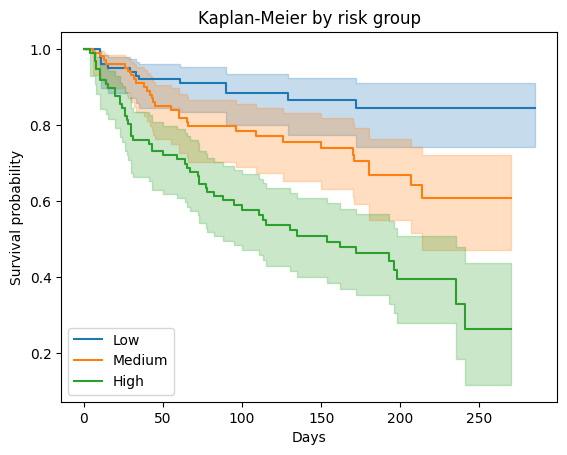

In [4]:
splits = list(cv.split(X, y))[:5]
group = pd.Series(index=data.index, dtype=object)

for train_idx, test_idx in splits:
    train = data.iloc[train_idx].copy()
    test = data.iloc[test_idx].copy()

    mu = train[feats].mean()
    sd = train[feats].std()
    train[feats] = (train[feats] - mu) / sd
    test[feats] = (test[feats] - mu) / sd

    cph = CoxPHFitter()
    cph.fit(train[feats + ["time", "DEATH_EVENT"]], duration_col="time", event_col="DEATH_EVENT")

    risk_train = cph.predict_partial_hazard(train[feats])
    low_cut, high_cut = np.quantile(risk_train, [1/3, 2/3])

    risk_test = cph.predict_partial_hazard(test[feats]).values
    g = np.where(risk_test <= low_cut, "Low", np.where(risk_test <= high_cut, "Medium", "High"))
    group.iloc[test_idx] = g

data["group"] = group

summary = data.groupby("group").agg(
    patients=("DEATH_EVENT", "size"),
    deaths=("DEATH_EVENT", "sum"),
    mortality=("DEATH_EVENT", "mean"),
).loc[["Low", "Medium", "High"]]
print(summary.round(3))

lr = multivariate_logrank_test(data["time"], data["group"], data["DEATH_EVENT"])
print("Log-rank p-value:", lr.p_value)

kmf = KaplanMeierFitter()
for name in ["Low", "Medium", "High"]:
    sub = data[data["group"] == name]
    kmf.fit(sub["time"], sub["DEATH_EVENT"], label=name)
    kmf.plot_survival_function()
plt.xlabel("Days")
plt.ylabel("Survival probability")
plt.title("Kaplan-Meier by risk group")
plt.savefig("km_risk_groups.png", dpi=300, bbox_inches="tight")
plt.show()

4. Full Cox model: hazard ratios

In [5]:
data_s = data[feats + ["time", "DEATH_EVENT"]].copy()
data_s[feats] = (data_s[feats] - data_s[feats].mean()) / data_s[feats].std()

cph_all = CoxPHFitter()
cph_all.fit(data_s, duration_col="time", event_col="DEATH_EVENT")

hr = cph_all.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
hr.columns = ["HR", "CI low", "CI high", "p"]
hr.sort_values("HR", ascending=False).round(3)

,HR,CI low,CI high,p
covariate,,,,
age,1.737,1.397,2.158,0.000
serum_creatinine,1.394,1.209,1.607,0.000
anaemia,1.256,1.018,1.551,0.034
high_blood_pressure,1.255,1.025,1.537,0.028
creatinine_phosphokinase,1.239,1.026,1.496,0.026
diabetes,1.072,0.863,1.330,0.531
smoking,1.062,0.844,1.337,0.608
platelets,0.956,0.770,1.186,0.681
sex,0.893,0.705,1.130,0.345


5. Variable selection frequency (RF top-5, correlation top-5)

In [6]:
rf_counts = Counter()
corr_counts = Counter()

for train_idx, _ in cv.split(X, y):
    Xt = X.iloc[train_idx]
    yt = y.iloc[train_idx]
    rf_counts.update(X.columns[TopKRandomForest(k=5).fit(Xt, yt).selected_])
    corr_counts.update(X.columns[TopKCorrelation(k=5).fit(Xt, yt).selected_])

freq = pd.DataFrame({
    "RF top5 (of 50)": pd.Series(rf_counts),
    "Corr top5 (of 50)": pd.Series(corr_counts),
}).fillna(0).astype(int).sort_values("RF top5 (of 50)", ascending=False)
freq

,RF top5 (of 50),Corr top5 (of 50)
age,50,50
ejection_fraction,50,50
serum_creatinine,50,50
platelets,49,7
creatinine_phosphokinase,47,17
serum_sodium,4,50
anaemia,0,9
high_blood_pressure,0,17


 6. Cox stratified by ejection fraction, and PH test

In [7]:
data_st = data_s.copy()
data_st["ef_group"] = pd.qcut(data["ejection_fraction"], 3, labels=False)
data_st = data_st.drop(columns=["ejection_fraction"])

cph_st = CoxPHFitter()
cph_st.fit(data_st, duration_col="time", event_col="DEATH_EVENT", strata=["ef_group"])

ph_st = proportional_hazard_test(cph_st, data_st, time_transform="rank")
ph_st.print_summary(decimals=3)

cph_st.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].round(3)

,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,
age,1.734,1.395,2.156,0.000
anaemia,1.227,0.992,1.516,0.059
creatinine_phosphokinase,1.195,0.986,1.447,0.069
diabetes,1.051,0.847,1.305,0.649
high_blood_pressure,1.242,1.013,1.523,0.037
platelets,0.951,0.763,1.186,0.658
serum_creatinine,1.309,1.147,1.494,0.000
serum_sodium,0.801,0.662,0.968,0.022
sex,0.958,0.758,1.211,0.720


In [8]:
ph = proportional_hazard_test(cph_all, data_s, time_transform="rank")
ph.print_summary(decimals=3)

 7. C-index and ROC-AUC: survival models vs classifiers

In [9]:
def run_models(cols):
    out = {n: {"c": [], "auc": []} for n in ["Cox", "RSF", "LR", "RF"]}
    for train_idx, test_idx in cv.split(X, y):
        train = data.iloc[train_idx]
        test = data.iloc[test_idx]
        y_te = test["DEATH_EVENT"]
        s = {}

        mu = train[cols].mean()
        sd = train[cols].std()
        tr_s = train[cols + ["time", "DEATH_EVENT"]].copy()
        te_s = test[cols].copy()
        tr_s[cols] = (train[cols] - mu) / sd
        te_s[cols] = (test[cols] - mu) / sd
        cph = CoxPHFitter().fit(tr_s, duration_col="time", event_col="DEATH_EVENT")
        s["Cox"] = cph.predict_partial_hazard(te_s).values

        rsf = RandomSurvivalForest(n_estimators=100, min_samples_leaf=10, random_state=42, n_jobs=-1)
        rsf.fit(train[cols], Surv.from_arrays(train["DEATH_EVENT"].astype(bool), train["time"]))
        s["RSF"] = rsf.predict(test[cols])

        lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
        lr.fit(train[cols], train["DEATH_EVENT"])
        s["LR"] = lr.predict_proba(test[cols])[:, 1]

        rf = make_pipeline(StandardScaler(), RandomForestClassifier(random_state=42))
        rf.fit(train[cols], train["DEATH_EVENT"])
        s["RF"] = rf.predict_proba(test[cols])[:, 1]

        for name, score in s.items():
            out[name]["c"].append(concordance_index(test["time"], -score, y_te))
            out[name]["auc"].append(roc_auc_score(y_te, score))
    return out

def nadeau_bengio(a, b, ratio=0.25):
    d = np.array(a) - np.array(b)
    k = len(d)
    t = d.mean() / np.sqrt((1 / k + ratio) * d.var(ddof=1))
    return d.mean(), 2 * stats.t.sf(abs(t), k - 1)

sets = {"All 11": feats, "2 feat": ["serum_creatinine", "ejection_fraction"]}
all_out = {}
for set_name, cols in sets.items():
    all_out[set_name] = run_models(cols)

summary_rows = []
pair_rows = []
for set_name, out in all_out.items():
    for name, v in out.items():
        summary_rows.append({
            "Features": set_name, "Model": name,
            "C-index": f"{np.mean(v['c']):.3f} ± {np.std(v['c']):.3f}",
            "ROC-AUC": f"{np.mean(v['auc']):.3f} ± {np.std(v['auc']):.3f}",
        })
    for m1, m2 in combinations(out.keys(), 2):
        for metric, key in [("C-index", "c"), ("ROC-AUC", "auc")]:
            diff, p = nadeau_bengio(out[m1][key], out[m2][key])
            pair_rows.append({
                "Features": set_name, "Comparison": f"{m1} - {m2}", "Metric": metric,
                "Mean diff": round(diff, 3), "p": round(p, 4), "p (Bonferroni)": round(min(p * 12, 1), 4),
            })

print(pd.DataFrame(summary_rows).to_string(index=False))
print()
print(pd.DataFrame(pair_rows).to_string(index=False))

Features Model       C-index       ROC-AUC
  All 11   Cox 0.700 ± 0.058 0.748 ± 0.060
  All 11   RSF 0.731 ± 0.058 0.799 ± 0.060
  All 11    LR 0.703 ± 0.061 0.760 ± 0.061
  All 11    RF 0.720 ± 0.057 0.786 ± 0.055
  2 feat   Cox 0.675 ± 0.077 0.748 ± 0.076
  2 feat   RSF 0.728 ± 0.057 0.798 ± 0.061
  2 feat    LR 0.681 ± 0.072 0.756 ± 0.072
  2 feat    RF 0.743 ± 0.052 0.802 ± 0.051

Features Comparison  Metric  Mean diff      p  p (Bonferroni)
  All 11  Cox - RSF C-index     -0.031 0.1948          1.0000
  All 11  Cox - RSF ROC-AUC     -0.050 0.0478          0.5737
  All 11   Cox - LR C-index     -0.003 0.7487          1.0000
  All 11   Cox - LR ROC-AUC     -0.011 0.2970          1.0000
  All 11   Cox - RF C-index     -0.020 0.3607          1.0000
  All 11   Cox - RF ROC-AUC     -0.038 0.0991          1.0000
  All 11   RSF - LR C-index      0.027 0.2144          1.0000
  All 11   RSF - LR ROC-AUC      0.039 0.0826          0.9909
  All 11   RSF - RF C-index      0.011 0.4634         

8. Cox risk groups over 10 repetitions

In [10]:

splits = list(cv.split(X, y))
horizon = 100
rows = []

for r in range(10):
    group = pd.Series(index=data.index, dtype=object)
    for train_idx, test_idx in splits[r * 5:(r + 1) * 5]:
        train = data.iloc[train_idx].copy()
        test = data.iloc[test_idx].copy()
        mu = train[feats].mean()
        sd = train[feats].std()
        train[feats] = (train[feats] - mu) / sd
        test[feats] = (test[feats] - mu) / sd

        cph = CoxPHFitter().fit(train[feats + ["time", "DEATH_EVENT"]], duration_col="time", event_col="DEATH_EVENT")
        lo, hi = np.quantile(cph.predict_partial_hazard(train[feats]), [1 / 3, 2 / 3])
        risk_test = cph.predict_partial_hazard(test[feats]).values
        group.iloc[test_idx] = np.where(risk_test <= lo, "Low", np.where(risk_test <= hi, "Medium", "High"))

    d = data[["time", "DEATH_EVENT"]].copy()
    d["Medium"] = (group == "Medium").astype(int)
    d["High"] = (group == "High").astype(int)
    s = CoxPHFitter().fit(d, duration_col="time", event_col="DEATH_EVENT").summary
    logrank_p = multivariate_logrank_test(data["time"], group, data["DEATH_EVENT"]).p_value

    row = {"repeat": r + 1}
    for g in ["Low", "Medium", "High"]:
        m = group == g
        row["n_" + g] = int(m.sum())
        row["mortality_" + g] = round(data.loc[m, "DEATH_EVENT"].mean(), 3)
        row["KM_S100_" + g] = round(float(KaplanMeierFitter().fit(data.loc[m, "time"], data.loc[m, "DEATH_EVENT"]).predict(horizon)), 3)
    for g in ["Medium", "High"]:
        row["HR_" + g] = round(s.loc[g, "exp(coef)"], 2)
        row["CI_low_" + g] = round(s.loc[g, "exp(coef) lower 95%"], 2)
        row["CI_high_" + g] = round(s.loc[g, "exp(coef) upper 95%"], 2)
    row["logrank_p"] = logrank_p
    rows.append(row)

rep_df = pd.DataFrame(rows)
print(rep_df.to_string(index=False))
print()
print(rep_df.drop(columns="repeat").agg(["mean", "std", "min", "max"]).round(3).T)

 repeat  n_Low  mortality_Low  KM_S100_Low  n_Medium  mortality_Medium  KM_S100_Medium  n_High  mortality_High  KM_S100_High  HR_Medium  CI_low_Medium  CI_high_Medium  HR_High  CI_low_High  CI_high_High    logrank_p
      1    100          0.130        0.883       102             0.294           0.785      97           0.546         0.577       2.39           1.25            4.58     5.28         2.87          9.69 3.749682e-09
      2    100          0.120        0.909        99             0.303           0.757     100           0.540         0.587       2.72           1.39            5.32     5.81         3.10         10.87 1.486970e-09
      3    103          0.117        0.897        92             0.304           0.751     104           0.538         0.603       2.89           1.47            5.67     5.92         3.17         11.07 1.009578e-09
      4    101          0.099        0.917        99             0.323           0.758      99           0.545         0.572       3.68 

9. Time-dependent AUC and integrated Brier score (Cox, RSF vs Kaplan-Meier)

In [11]:
times = np.arange(40, 181, 10)
res_t = {n: {"auc_t": [], "auc_mean": [], "ibs": []} for n in ["Cox", "RSF"]}
res_t["KM (no variables)"] = {"auc_t": [], "auc_mean": [], "ibs": []}

for train_idx, test_idx in cv.split(X, y):
    train = data.iloc[train_idx]
    test = data.iloc[test_idx]
    y_tr = Surv.from_arrays(train["DEATH_EVENT"].astype(bool), train["time"])
    y_te = Surv.from_arrays(test["DEATH_EVENT"].astype(bool), test["time"])

    # Cox
    mu = train[feats].mean()
    sd = train[feats].std()
    tr_s = train[feats + ["time", "DEATH_EVENT"]].copy()
    te_s = test[feats].copy()
    tr_s[feats] = (train[feats] - mu) / sd
    te_s[feats] = (test[feats] - mu) / sd
    cph = CoxPHFitter().fit(tr_s, duration_col="time", event_col="DEATH_EVENT")
    risk_cox = cph.predict_partial_hazard(te_s).values
    surv_cox = cph.predict_survival_function(te_s, times=times).T.values

    # RSF
    rsf = RandomSurvivalForest(n_estimators=100, min_samples_leaf=10, random_state=42, n_jobs=-1)
    rsf.fit(train[feats], y_tr)
    risk_rsf = rsf.predict(test[feats])
    surv_rsf = np.vstack([fn(times) for fn in rsf.predict_survival_function(test[feats])])

    # Kaplan-Meier (no variables)
    s0 = KaplanMeierFitter().fit(train["time"], train["DEATH_EVENT"]).predict(times).values
    surv_km = np.tile(s0, (len(test), 1))

    for name, risk, surv in [("Cox", risk_cox, surv_cox), ("RSF", risk_rsf, surv_rsf), ("KM (no variables)", risk_cox, surv_km)]:
        if name != "KM (no variables)":
            auc_t, _ = cumulative_dynamic_auc(y_tr, y_te, risk, times)
            res_t[name]["auc_t"].append(auc_t)
            res_t[name]["auc_mean"].append(np.mean(auc_t))
        res_t[name]["ibs"].append(integrated_brier_score(y_tr, y_te, surv, times))

rows_t = []
for name, v in res_t.items():
    row = {"Model": name}
    if v["auc_mean"]:
        row["Mean time-dep. AUC"] = f"{np.mean(v['auc_mean']):.3f} ± {np.std(v['auc_mean']):.3f}"
        mean_by_time = np.mean(v["auc_t"], axis=0)
        for t, a in zip(times, mean_by_time):
            row[f"AUC({t}d)"] = round(a, 3)
    row["IBS"] = f"{np.mean(v['ibs']):.3f} ± {np.std(v['ibs']):.3f}"
    rows_t.append(row)

print(pd.DataFrame(rows_t).to_string(index=False))

            Model Mean time-dep. AUC  AUC(40d)  AUC(50d)  AUC(60d)  AUC(70d)  AUC(80d)  AUC(90d)  AUC(100d)  AUC(110d)  AUC(120d)  AUC(130d)  AUC(140d)  AUC(150d)  AUC(160d)  AUC(170d)  AUC(180d)           IBS
              Cox      0.711 ± 0.066     0.676     0.703     0.708     0.699     0.713     0.701      0.711      0.713      0.727      0.721      0.723      0.715      0.717      0.725      0.709 0.166 ± 0.019
              RSF      0.744 ± 0.063     0.692     0.717     0.728     0.729     0.733     0.739      0.757      0.756      0.768      0.753      0.758      0.748      0.749      0.759      0.766 0.161 ± 0.013
KM (no variables)                NaN       NaN       NaN       NaN       NaN       NaN       NaN        NaN        NaN        NaN        NaN        NaN        NaN        NaN        NaN        NaN 0.187 ± 0.011


10. SHAP vs LIME agreement, Random Forest classifier (supplementary)

In [12]:
splits_all = list(cv.split(X, y))
chosen = splits_all[::5]
rows_x = []

for k, (train_idx, test_idx) in enumerate(chosen):
    X_tr = X.iloc[train_idx]
    X_te = X.iloc[test_idx]
    y_tr = y.iloc[train_idx]

    rf_x = RandomForestClassifier(random_state=42, class_weight="balanced").fit(X_tr, y_tr)

    sv = shap.TreeExplainer(rf_x).shap_values(X_te)
    if isinstance(sv, list):
        sv = sv[1]
    elif sv.ndim == 3:
        sv = sv[:, :, 1]

    lime_exp = LimeTabularExplainer(
        X_tr.values, feature_names=feats, class_names=["Survived", "Died"],
        mode="classification", discretize_continuous=False, random_state=42
    )

    rhos, overlaps = [], []
    for i in range(len(X_te)):
        exp = lime_exp.explain_instance(
            X_te.values[i],
            lambda a: rf_x.predict_proba(pd.DataFrame(a, columns=feats)),
            num_features=len(feats), labels=(1,)
        )
        lime_w = np.zeros(len(feats))
        for idx, w in exp.as_map()[1]:
            lime_w[idx] = w

        rho, _ = spearmanr(np.abs(sv[i]), np.abs(lime_w))
        rhos.append(rho)
        top_shap = set(np.argsort(-np.abs(sv[i]))[:3])
        top_lime = set(np.argsort(-np.abs(lime_w))[:3])
        overlaps.append(len(top_shap & top_lime))

    rows_x.append({
        "split": k + 1,
        "patients": len(X_te),
        "spearman_mean": np.mean(rhos),
        "top3_overlap_mean": np.mean(overlaps),
        "share_2_of_3": np.mean(np.array(overlaps) >= 2),
    })
    print("done split", k + 1, "of", len(chosen))

agree_df = pd.DataFrame(rows_x)
print(agree_df.round(3).to_string(index=False))
print()
print(agree_df.drop(columns=["split", "patients"]).agg(["mean", "std", "min", "max"]).round(3).T)

done split 1 of 10
done split 2 of 10
done split 3 of 10
done split 4 of 10
done split 5 of 10
done split 6 of 10
done split 7 of 10
done split 8 of 10
done split 9 of 10
done split 10 of 10
 split  patients  spearman_mean  top3_overlap_mean  share_2_of_3
     1        60          0.665              2.333         0.900
     2        60          0.592              2.150         0.933
     3        60          0.686              2.100         0.867
     4        60          0.740              2.183         0.950
     5        60          0.608              2.350         0.933
     6        60          0.601              2.350         0.983
     7        60          0.637              2.117         0.850
     8        60          0.742              2.133         0.867
     9        60          0.664              2.367         0.983
    10        60          0.709              2.050         0.867

                    mean    std    min    max
spearman_mean      0.664  0.055  0.592  0.742
t

11. Proportional hazards per variable, and early vs late effect of EF

In [13]:
# PH check: which variables violate proportional hazards?
ph_data = data[list(X.columns) + ["time", "DEATH_EVENT"]]

cph_ph = CoxPHFitter()
cph_ph.fit(ph_data, duration_col="time", event_col="DEATH_EVENT")

ph_res = proportional_hazard_test(cph_ph, ph_data, time_transform="rank")
ph_table = ph_res.summary.sort_values("p")
ph_table["violates (p<0.05)"] = ph_table["p"] < 0.05
print(ph_table[["test_statistic", "p", "violates (p<0.05)"]].round(4))

print("\nViolating variables:",
      list(ph_table.index[ph_table["p"] < 0.05]))

                          test_statistic       p  violates (p<0.05)
ejection_fraction                 6.2106  0.0127               True
serum_creatinine                  3.4754  0.0623              False
serum_sodium                      1.7323  0.1881              False
creatinine_phosphokinase          1.1069  0.2928              False
smoking                           0.3277  0.5670              False
sex                               0.2608  0.6096              False
platelets                         0.1138  0.7359              False
high_blood_pressure               0.1110  0.7390              False
age                               0.0297  0.8631              False
anaemia                           0.0081  0.9281              False
diabetes                          0.0002  0.9884              False

Violating variables: ['ejection_fraction']


In [14]:
# Time-varying effect of EF: HR in early vs late follow-up
cut = 100   # days; change if you prefer another cut-off
rows = []
for name, lo, hi in [("early (0-%d d)" % cut, 0, cut), ("late (>%d d)" % cut, cut, np.inf)]:
    d = ph_data[ph_data["time"] > lo].copy()          # still at risk at window start
    d["event_w"] = ((d["DEATH_EVENT"] == 1) & (d["time"] <= hi)).astype(int)
    d["time_w"] = np.minimum(d["time"], hi) - lo
    m = CoxPHFitter().fit(d.drop(columns=["time", "DEATH_EVENT"]),
                          duration_col="time_w", event_col="event_w")
    s = m.summary.loc["ejection_fraction"]
    rows.append({"Window": name, "N at risk": len(d), "Events": int(d["event_w"].sum()),
                 "HR per 1 unit EF": round(s["exp(coef)"], 3),
                 "95% CI": f"{s['exp(coef) lower 95%']:.3f} to {s['exp(coef) upper 95%']:.3f}",
                 "p": round(s["p"], 4)})
print(pd.DataFrame(rows).to_string(index=False))

         Window  N at risk  Events  HR per 1 unit EF         95% CI      p
early (0-100 d)        299      72             0.960 0.938 to 0.982 0.0004
  late (>100 d)        172      24             0.904 0.857 to 0.953 0.0002


In [15]:
# Test of EF x time interaction (is the EF effect different early vs late?)

cut = 100
d = ph_data.reset_index(drop=True).copy()
d["id"] = range(len(d))

# Early episode: from 0 to min(time, cut)
early = d.copy()
early["start"] = 0
early["stop"] = np.minimum(early["time"], cut)
early["event"] = ((early["DEATH_EVENT"] == 1) & (early["time"] <= cut)).astype(int)
early["EF_x_late"] = 0

# Late episode: only patients still at risk after the cut
late = d[d["time"] > cut].copy()
late["start"] = cut
late["stop"] = late["time"]
late["event"] = late["DEATH_EVENT"]
late["EF_x_late"] = late["ejection_fraction"]

long_df = pd.concat([early, late], ignore_index=True)
cols_ctv = list(X.columns) + ["EF_x_late", "id", "start", "stop", "event"]

ctv = CoxTimeVaryingFitter()
ctv.fit(long_df[cols_ctv], id_col="id", event_col="event",
        start_col="start", stop_col="stop")
b = ctv.params_
V = pd.DataFrame(np.asarray(ctv.variance_matrix_), index=b.index, columns=b.index)
b1, b2 = b["ejection_fraction"], b["EF_x_late"]
se_late = np.sqrt(V.loc["ejection_fraction", "ejection_fraction"]
                  + V.loc["EF_x_late", "EF_x_late"]
                  + 2 * V.loc["ejection_fraction", "EF_x_late"])
ci_low, ci_high = np.exp(b1 + b2 - 1.96 * se_late), np.exp(b1 + b2 + 1.96 * se_late)

summ = ctv.summary
print("Early HR per 1 unit EF: %.3f" % np.exp(b1))
print("Late  HR per 1 unit EF: %.3f (95%% CI %.3f to %.3f)" % (np.exp(b1 + b2), ci_low, ci_high))
print("Ratio late/early (interaction): %.3f (95%% CI %.3f to %.3f), p = %.4f" % (
    summ.loc["EF_x_late", "exp(coef)"],
    summ.loc["EF_x_late", "exp(coef) lower 95%"],
    summ.loc["EF_x_late", "exp(coef) upper 95%"],
    summ.loc["EF_x_late", "p"]))

Early HR per 1 unit EF: 0.959
Late  HR per 1 unit EF: 0.926 (95% CI 0.883 to 0.971)
Ratio late/early (interaction): 0.966 (95% CI 0.917 to 1.017), p = 0.1861


12. Time-dependent AUC, four models, 50 folds

In [16]:
# Time-dependent AUC for all four models on the same 50 folds + grid check
grid = np.arange(40, 181, 10)
var_sets = {"11 variables": list(X.columns),
            "2 variables": ["serum_creatinine", "ejection_fraction"]}

surv_y = Surv.from_arrays(event=data["DEATH_EVENT"].astype(bool).values,
                          time=data["time"].values)

def risk_scores(name, cols, tr, te):
    Xtr, Xte = data.iloc[tr][cols], data.iloc[te][cols]
    ytr = data["DEATH_EVENT"].iloc[tr]
    if name == "LR":
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
        return m.predict_proba(Xte)[:, 1]
    if name == "RF":
        m = RandomForestClassifier(random_state=42).fit(Xtr, ytr)
        return m.predict_proba(Xte)[:, 1]
    if name == "Cox":
        sc = StandardScaler().fit(Xtr)
        dtr = pd.DataFrame(sc.transform(Xtr), columns=cols, index=Xtr.index)
        dtr["time"] = data["time"].iloc[tr].values
        dtr["event"] = ytr.values
        m = CoxPHFitter().fit(dtr, duration_col="time", event_col="event")
        dte = pd.DataFrame(sc.transform(Xte), columns=cols, index=Xte.index)
        return m.predict_partial_hazard(dte).values
    if name == "RSF":
        m = RandomSurvivalForest(n_estimators=100, min_samples_leaf=10,
                                 random_state=42, n_jobs=-1).fit(Xtr, surv_y[tr])
        return m.predict(Xte)

res, bad_folds, lo_list, hi_list = {}, 0, [], []
for k, (tr, te) in enumerate(cv.split(X, y)):
    t_te = data["time"].iloc[te].values
    lo_list.append(t_te.min()); hi_list.append(t_te.max())
    if not (t_te.min() <= grid[0] and grid[-1] < t_te.max()):
        bad_folds += 1
        continue
    for vs_name, cols in var_sets.items():
        for name in ["LR", "RF", "Cox", "RSF"]:
            r = risk_scores(name, cols, tr, te)
            auc_t, _ = cumulative_dynamic_auc(surv_y[tr], surv_y[te], r, grid)
            res.setdefault((name, vs_name), []).append(auc_t)

print(f"Grid {grid[0]}-{grid[-1]} d | min test follow-up per fold: "
      f"{min(lo_list):.0f}-{max(lo_list):.0f} d | max: {min(hi_list):.0f}-{max(hi_list):.0f} d")
print("Folds where the grid was outside follow-up:", bad_folds, "of 50\n")

rows = []
for (name, vs_name), arrs in res.items():
    a = np.array(arrs)              # folds x times
    per_fold = a.mean(axis=1)       # mean AUC(t) over grid per fold
    rows.append({"Variables": vs_name, "Model": name,
                 "Mean time-dep AUC (40-180 d)": f"{per_fold.mean():.3f} ± {per_fold.std():.3f}"})
print(pd.DataFrame(rows).sort_values(["Variables", "Model"]).to_string(index=False))

Grid 40-180 d | min test follow-up per fold: 4-11 d | max: 247-285 d
Folds where the grid was outside follow-up: 0 of 50

   Variables Model Mean time-dep AUC (40-180 d)
11 variables   Cox                0.711 ± 0.066
11 variables    LR                0.714 ± 0.070
11 variables    RF                0.730 ± 0.060
11 variables   RSF                0.744 ± 0.063
 2 variables   Cox                0.669 ± 0.087
 2 variables    LR                0.676 ± 0.082
 2 variables    RF                0.761 ± 0.058
 2 variables   RSF                0.739 ± 0.063


 13. Corrected resampled t-test (12 comparisons, Bonferroni)

In [17]:
# Nadeau-Bengio corrected resampled t-test on per-fold mean time-dependent AUC

models4 = ["Cox", "LR", "RF", "RSF"]
J = 50                        # 5 folds x 10 repeats
corr = 1 / J + 1 / 4          # n_test / n_train = 1/4 for 5-fold CV
n_comp = 2 * len(list(combinations(models4, 2)))   # 12 comparisons in total

rows = []
for vs_name in var_sets:
    pf = {m: np.array(res[(m, vs_name)]).mean(axis=1) for m in models4}
    for a, b in combinations(models4, 2):
        d = pf[a] - pf[b]
        t = d.mean() / np.sqrt(d.var(ddof=1) * corr)
        p = 2 * stats.t.sf(abs(t), J - 1)
        rows.append({"Variables": vs_name, "Comparison": f"{a} vs {b}",
                     "Mean diff": round(d.mean(), 3), "t": round(t, 2),
                     "p": round(p, 4), "p Bonferroni": round(min(p * n_comp, 1), 4)})

out = pd.DataFrame(rows)
out["Significant (adj p<0.05)"] = out["p Bonferroni"] < 0.05
print(f"Number of comparisons corrected by Bonferroni: {n_comp}\n")
print(out.to_string(index=False))

Number of comparisons corrected by Bonferroni: 12

   Variables Comparison  Mean diff     t      p  p Bonferroni  Significant (adj p<0.05)
11 variables  Cox vs LR     -0.003 -0.27 0.7879        1.0000                     False
11 variables  Cox vs RF     -0.019 -0.75 0.4544        1.0000                     False
11 variables Cox vs RSF     -0.033 -1.27 0.2092        1.0000                     False
11 variables   LR vs RF     -0.016 -0.60 0.5488        1.0000                     False
11 variables  LR vs RSF     -0.030 -1.21 0.2333        1.0000                     False
11 variables  RF vs RSF     -0.014 -0.80 0.4274        1.0000                     False
 2 variables  Cox vs LR     -0.007 -0.90 0.3703        1.0000                     False
 2 variables  Cox vs RF     -0.092 -2.31 0.0253        0.3031                     False
 2 variables Cox vs RSF     -0.070 -2.22 0.0308        0.3700                     False
 2 variables   LR vs RF     -0.085 -2.33 0.0241        0.2891        

14. SHAP on the Random Survival Forest

PermutationExplainer explainer: 300it [12:37,  2.57s/it]


Mean |SHAP| (RSF risk score):

serum_creatinine            5.308
ejection_fraction           3.577
age                         3.417
high_blood_pressure         1.090
serum_sodium                1.016
anaemia                     0.746
platelets                   0.698
creatinine_phosphokinase    0.610
diabetes                    0.204
smoking                     0.193
sex                         0.118


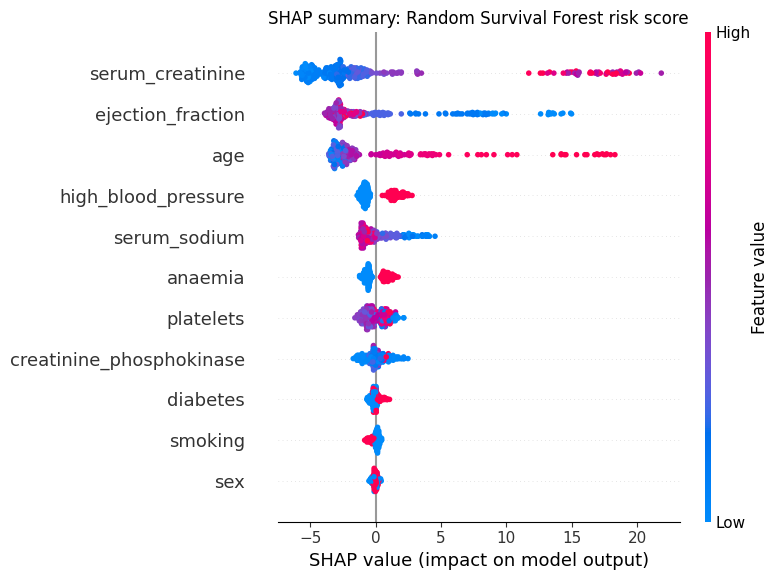

In [18]:
# SHAP on the survival model itself (RSF risk score)
rsf_final = RandomSurvivalForest(n_estimators=100, min_samples_leaf=10,
                                 random_state=42, n_jobs=-1).fit(X, surv_y)

masker = shap.maskers.Independent(X, max_samples=100)
explainer = shap.Explainer(rsf_final.predict, masker, seed=42)
sv = explainer(X)                      # permutation SHAP on the RSF risk score

imp = pd.Series(np.abs(sv.values).mean(axis=0), index=X.columns).sort_values(ascending=False)
print("Mean |SHAP| (RSF risk score):\n")
print(imp.round(3).to_string())

shap.summary_plot(sv.values, X, show=False)
plt.title("SHAP summary: Random Survival Forest risk score")
plt.tight_layout()
plt.savefig("shap_rsf_summary.png", dpi=300, bbox_inches="tight")
plt.show()

15. Patient-level stability of Cox risk groups

In [19]:
# Patient-level stability of Cox risk groups across the 10 repetitions
cols = list(X.columns)
n_rep = 10
groups = np.full((len(data), n_rep), -1)       # patients x repetitions

for k, (tr, te) in enumerate(cv.split(X, y)):
    rep = k // 5                               # 5 folds per repetition
    Xtr, Xte = data.iloc[tr][cols], data.iloc[te][cols]
    sc = StandardScaler().fit(Xtr)
    dtr = pd.DataFrame(sc.transform(Xtr), columns=cols, index=Xtr.index)
    dtr["time"] = data["time"].iloc[tr].values
    dtr["event"] = data["DEATH_EVENT"].iloc[tr].values
    m = CoxPHFitter().fit(dtr, duration_col="time", event_col="event")

    r_tr = m.predict_partial_hazard(dtr[cols]).values
    cuts = np.quantile(r_tr, [1/3, 2/3])       # cut-points from training-fold risk
    dte = pd.DataFrame(sc.transform(Xte), columns=cols, index=Xte.index)
    r_te = m.predict_partial_hazard(dte).values
    groups[te, rep] = np.digitize(r_te, cuts)  # 0 low, 1 medium, 2 high

assert (groups >= 0).all()

# share of repetitions in the patient's most frequent group
modal_share = np.array([np.bincount(g, minlength=3).max() / n_rep for g in groups])
modal_group = np.array([np.bincount(g, minlength=3).argmax() for g in groups])

print(f"Mean share of repetitions in the same (most frequent) group: "
      f"{modal_share.mean():.2f} ± {modal_share.std():.2f}")
print(f"Patients in the same group in all 10 repetitions: {(modal_share == 1).mean():.1%}")
print(f"Patients in the same group in at least 8 of 10:   {(modal_share >= 0.8).mean():.1%}")

names = {0: "Low", 1: "Medium", 2: "High"}
rows = []
for g in range(3):
    s = modal_share[modal_group == g]
    rows.append({"Usual group": names[g], "Patients": len(s),
                 "Mean share": round(s.mean(), 2),
                 ">=8/10 same group": f"{(s >= 0.8).mean():.1%}"})
print()
print(pd.DataFrame(rows).to_string(index=False))

Mean share of repetitions in the same (most frequent) group: 0.89 ± 0.15
Patients in the same group in all 10 repetitions: 55.2%
Patients in the same group in at least 8 of 10:   78.6%

Usual group  Patients  Mean share >=8/10 same group
        Low       104        0.91             82.7%
     Medium       101        0.83             65.3%
       High        94        0.93             88.3%


16. Censoring before the 100-day horizon

In [20]:
# Patients censored before the 100-day horizon
h = 100
cens_before = ((data["DEATH_EVENT"] == 0) & (data["time"] < h)).sum()
died_before = ((data["DEATH_EVENT"] == 1) & (data["time"] < h)).sum()
n_total, n_cens = len(data), (data["DEATH_EVENT"] == 0).sum()

print(f"Censored before {h} days: {cens_before} of {n_total} patients "
      f"({cens_before / n_total:.1%} of all; {cens_before / n_cens:.1%} of the {n_cens} censored)")
print(f"Died before {h} days: {died_before}")
print(f"Alive and followed to {h} days or longer: "
      f"{((data['time'] >= h)).sum()} of {n_total}")

Censored before 100 days: 55 of 299 patients (18.4% of all; 27.1% of the 203 censored)
Died before 100 days: 71
Alive and followed to 100 days or longer: 173 of 299


17. Calibration at 100 days

Cox (Q1 = highest predicted risk; counts averaged over 10 repetitions)
    Predicted S(100)  Observed KM S(100)  Patients  Deaths by 100 d
Q1             0.427               0.509      60.0             28.2
Q2             0.705               0.675      60.0             19.1
Q3             0.815               0.792      59.0             11.7
Q4             0.889               0.860      60.0              8.0
Q5             0.949               0.914      60.0              5.0

RSF (Q1 = highest predicted risk; counts averaged over 10 repetitions)
    Predicted S(100)  Observed KM S(100)  Patients  Deaths by 100 d
Q1             0.535               0.496      60.0             29.2
Q2             0.685               0.579      60.0             23.9
Q3             0.786               0.857      59.0              8.2
Q4             0.849               0.910      60.0              5.4
Q5             0.904               0.910      60.0              5.3



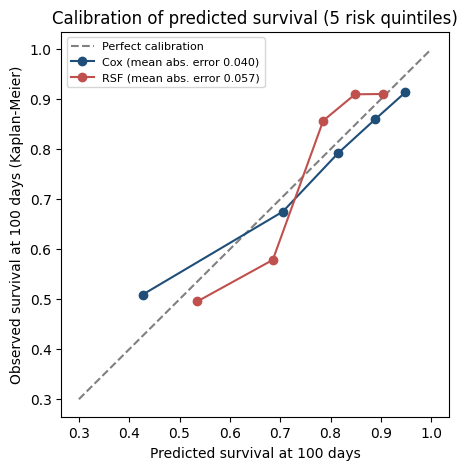

In [21]:
horizon = 100
splits_all = list(cv.split(X, y))
n = len(data)
cal = {"Cox": [], "RSF": []}
died_by_h = ((data["DEATH_EVENT"] == 1) & (data["time"] <= horizon)).values

for r in range(10):
    pred = {"Cox": np.zeros(n), "RSF": np.zeros(n)}
    for train_idx, test_idx in splits_all[r * 5:(r + 1) * 5]:
        train = data.iloc[train_idx]
        test = data.iloc[test_idx]

        mu = train[feats].mean()
        sd = train[feats].std()
        tr_s = train[feats + ["time", "DEATH_EVENT"]].copy()
        te_s = test[feats].copy()
        tr_s[feats] = (train[feats] - mu) / sd
        te_s[feats] = (test[feats] - mu) / sd
        cph = CoxPHFitter().fit(tr_s, duration_col="time", event_col="DEATH_EVENT")
        pred["Cox"][test_idx] = cph.predict_survival_function(te_s, times=[horizon]).iloc[0].values

        rsf = RandomSurvivalForest(n_estimators=100, min_samples_leaf=10, random_state=42, n_jobs=-1)
        rsf.fit(train[feats], Surv.from_arrays(train["DEATH_EVENT"].astype(bool), train["time"]))
        pred[ "RSF"][test_idx] = [fn(horizon) for fn in rsf.predict_survival_function(test[feats])]

    for name in ["Cox", "RSF"]:
        grp = pd.qcut(pred[name], 5, labels=False, duplicates="drop")
        pts = []
        for g in np.unique(grp):
            m = grp == g
            obs = KaplanMeierFitter().fit(data["time"][m], data["DEATH_EVENT"][m]).predict(horizon)
            pts.append([pred[name][m].mean(), float(obs), m.sum(), died_by_h[m].sum()])
        cal[name].append(np.array(pts))

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0.3, 1], [0.3, 1], "--", color="gray", label="Perfect calibration")
for name, color in [("Cox", "#1f4e79"), ("RSF", "#c0504d")]:
    mean_cal = np.mean(cal[name], axis=0)
    err = np.mean(np.abs(mean_cal[:, 0] - mean_cal[:, 1]))
    ax.plot(mean_cal[:, 0], mean_cal[:, 1], marker="o", color=color,
            label=f"{name} (mean abs. error {err:.3f})")
    tab = pd.DataFrame(mean_cal, columns=["Predicted S(100)", "Observed KM S(100)",
                                          "Patients", "Deaths by 100 d"])
    tab.index = [f"Q{i+1}" for i in range(len(tab))]
    print(name, "(Q1 = highest predicted risk; counts averaged over 10 repetitions)")
    print(tab.round(3))
    print()
ax.set_xlabel("Predicted survival at 100 days")
ax.set_ylabel("Observed survival at 100 days (Kaplan-Meier)")
ax.set_title("Calibration of predicted survival (5 risk quintiles)")
ax.legend(loc="upper left", fontsize=8)
plt.savefig("calibration.png", dpi=300, bbox_inches="tight")
plt.show()

18. Stability of SHAP ranking across folds

In [22]:
splits_all = list(cv.split(X, y))
chosen = splits_all[::10]          # 5 طيّات من 5 تكرارات مختلفة
imp_folds = {}

for k, (train_idx, test_idx) in enumerate(chosen):
    X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
    tr, te = data.iloc[train_idx], data.iloc[test_idx]
    surv_tr = Surv.from_arrays(tr["DEATH_EVENT"].astype(bool), tr["time"])

    rsf_k = RandomSurvivalForest(n_estimators=100, min_samples_leaf=10,
                                 random_state=42, n_jobs=-1).fit(X_tr, surv_tr)
    masker_k = shap.maskers.Independent(X_tr, max_samples=100)
    expl_k = shap.Explainer(rsf_k.predict, masker_k, seed=42)
    sv_k = expl_k(X_te)
    imp_folds[f"Fold {k+1}"] = np.abs(sv_k.values).mean(axis=0)
    print("done fold", k + 1, "of", len(chosen))

imp_df = pd.DataFrame(imp_folds, index=X.columns)
rank_df = imp_df.rank(ascending=False).astype(int)
rank_df["All patients (cell 24)"] = imp.rank(ascending=False).reindex(X.columns).astype(int)
print("\nRank of each variable (1 = most important):")
print(rank_df.sort_values("All patients (cell 24)").to_string())

# Spearman agreement between folds
cols = list(imp_folds.keys())
pair = [spearmanr(imp_df[a], imp_df[b])[0] for a, b in combinations(cols, 2)]
print("\nSpearman between folds: mean %.3f, min %.3f, max %.3f" % (np.mean(pair), np.min(pair), np.max(pair)))

# How often each variable is in the top 3
top3 = Counter()
for c in cols:
    top3.update(imp_df[c].sort_values(ascending=False).index[:3])
print("\nTimes in top 3 (out of %d folds):" % len(cols))
print(pd.Series(top3).sort_values(ascending=False).to_string())

PermutationExplainer explainer: 61it [02:11,  2.35s/it]


done fold 1 of 5


PermutationExplainer explainer: 61it [02:01,  2.17s/it]


done fold 2 of 5


PermutationExplainer explainer: 61it [02:34,  2.72s/it]


done fold 3 of 5


PermutationExplainer explainer: 61it [02:06,  2.30s/it]


done fold 4 of 5


PermutationExplainer explainer: 61it [02:17,  2.46s/it]

done fold 5 of 5

Rank of each variable (1 = most important):
                          Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  All patients (cell 24)
serum_creatinine               1       1       1       1       1                       1
ejection_fraction              3       2       2       2       3                       2
age                            2       3       3       3       2                       3
high_blood_pressure            7       7       8       4       5                       4
serum_sodium                   4       4       6       5       4                       5
anaemia                        6       6       5       8       8                       6
platelets                      5       5       7       6       6                       7
creatinine_phosphokinase       8       8       4       7       7                       8
diabetes                       9       9      10      10      10                       9
smoking                       11      10       9

19. Software versions

In [23]:
import sys, importlib.metadata as md

print("Python", sys.version.split()[0])
for pkg in ["numpy", "pandas", "scipy", "scikit-learn", "scikit-survival",
            "lifelines", "xgboost", "shap", "lime", "matplotlib"]:
    print(f"{pkg}: {md.version(pkg)}")

Python 3.13.18
numpy: 2.4.6
pandas: 2.2.3
scipy: 1.16.3
scikit-learn: 1.9.1
scikit-survival: 0.28.0
lifelines: 0.30.3
xgboost: 3.4.1
shap: 0.54.1
lime: 0.2.0.1
matplotlib: 3.10.0
